# 콘크리트 균열 이미지 분류 (Image Classification) - ResNet18 Transfer Learning + Grad-CAM 시각화

콘크리트 표면 이미지 한 장을 입력받아 균열이 있는지(`crack`) 없는지(`intact`) 이진 분류(Binary Classification)를 수행합니다. 또한 설명 가능한 AI(XAI) 기법인 **Grad-CAM**을 통해 모델이 이미지의 어느 영역에 주목하여 판단을 내렸는지 히트맵으로 확인합니다.


## 1. 데이터셋 다운로드 경로 및 환경 변수 설정

* **공유 링크 설정 (`ZIP_URL`):** 구글 드라이브에서 데이터셋 압축 파일(`.zip`)을 `링크가 있는 모든 사용자` 권한으로 공유한 뒤 해당 URL(또는 파일 ID)을 입력합니다.
* **경로 변수 (`TASK`, `ZIP_PATH`, `DST`):** 압축 파일을 저장할 경로(`/content/01_classification.zip`)와 압축을 해제할 대상 디렉토리(`/content/classification`)를 지정합니다.
* *참고:* 파일 크기가 100MB를 초과할 경우 일반 `wget` 요청은 구글의 바이러스 검사 확인 페이지를 반환하므로, 구글 드라이브 링크는 `gdown`을 사용하고 직링크(Direct URL)는 `wget`을 사용하도록 분기 처리합니다.


In [1]:
# ==============================================================================
# [셀 1] 데이터셋 다운로드 URL 및 로컬 저장 경로 설정
# - 구글 드라이브 공유 링크(ZIP_URL)와 다운로드 받을 파일 경로(ZIP_PATH),
#   압축 해제 폴더 경로(DST)를 전역 변수로 정의합니다.
# ==============================================================================
DRIVE_ID = "1c5ca46KgfBWQF2IvQvlS5PTRCMWzYcw5"
ZIP_URL = "/".join(["https:", "", "drive.google.com", "file", "d", DRIVE_ID, "view?usp=sharing"])

TASK = "classification"
ZIP_PATH = "/content/01_classification.zip"
DST = f"/content/{TASK}"


## 2. 필수 패키지 설치
* 구글 드라이브 대용량 공유 파일을 인증 우회하여 다운로드할 수 있도록 지원하는 `gdown` 패키지를 설치합니다.


In [2]:
# ==============================================================================
# [셀 2] 구글 드라이브 파일 다운로드 유틸리티(gdown) 설치
# ==============================================================================
!pip install -q gdown


## 3. 데이터셋 압축 파일 다운로드, 압축 해제 및 GPU 디바이스 확인
* **다운로드 함수 (`fetch_zip`):**
  * 이미 정상적인 크기(> 10KB)의 압축 파일이 존재하면 재다운로드를 건너뛰어 실행 시간을 절약합니다.
  * URL에 `drive.google.com` 등이 포함되어 있으면 `gdown --fuzzy`를 실행하여 파일 ID를 자동 추출해 다운로드하고, 일반 웹 URL이면 `wget`으로 다운로드합니다.
* **클린 압축 해제 및 환경 점검:**
  * 기존 폴더(`DST`)를 삭제(`rm -rf`)한 후 `unzip`으로 깨끗하게 압축을 풀고, GPU(`cuda`) 인식 여부와 버전을 확인합니다.


In [3]:
# ==============================================================================
# [셀 3] 데이터셋 ZIP 파일 다운로드 함수 정의 및 실행
# - 기존 다운로드 파일 존재 여부를 확인하여 중복 다운로드를 방지합니다.
# - 구글 드라이브 링크 여부에 따라 gdown 또는 wget 명령어를 자동으로 선택해 실행합니다.
# ==============================================================================
from pathlib import Path
import os


def fetch_zip(url, dest):
    url = (url or "").strip()
    if not url or "여기에" in url:
        raise SystemExit(
            "위 셀 ZIP_URL에 구글 드라이브 공유 링크(또는 직접 zip 주소)를 넣는다."
        )

    is_drive = "drive.google.com" in url or "docs.google.com" in url

    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 10_000:
        print("이미 받은 파일이 있다:", dest, dest.stat().st_size, "bytes")
        return

    dest.parent.mkdir(parents=True, exist_ok=True)

    os.environ["ZIP_URL"] = url
    os.environ["ZIP_PATH"] = str(dest)
    if is_drive:
        !gdown --fuzzy "$ZIP_URL" -O "$ZIP_PATH"
    else:
        !wget -c -O "$ZIP_PATH" "$ZIP_URL"

    print("받음", dest, dest.stat().st_size, "bytes")


fetch_zip(ZIP_URL, ZIP_PATH)


Downloading...
From (original): https://drive.google.com/uc?id=1c5ca46KgfBWQF2IvQvlS5PTRCMWzYcw5
From (redirected): https://drive.google.com/uc?id=1c5ca46KgfBWQF2IvQvlS5PTRCMWzYcw5&confirm=t&uuid=d0ef3f1a-d606-49da-bb35-5cb87d1ff433
To: /content/01_classification.zip
100% 95.1M/95.1M [00:02<00:00, 43.5MB/s]
받음 /content/01_classification.zip 95055198 bytes


In [4]:
# ==============================================================================
# [셀 4] 기존 압축 해제 디렉토리 초기화 (충돌 방지)
# ==============================================================================
!rm -rf {DST}


In [5]:
# ==============================================================================
# [셀 5] 다운로드한 ZIP 압축 파일을 /content 경로에 압축 해제
# ==============================================================================
!unzip -q -o {ZIP_PATH} -d /content


In [6]:
# ==============================================================================
# [셀 6] 데이터 루트 경로 검증, GPU 디바이스 설정 및 이미지 출력 함수(show_img) 정의
# - 압축 해제된 폴더(ROOT)가 정상적으로 존재하는지 확인하고 CUDA 디바이스를 설정합니다.
# - 고해상도 이미지를 지정된 폭(width=900)에 맞춰 양선형 보간(BILINEAR)으로 리사이즈해
#   노트북 셀에 출력하는 유틸리티 함수를 정의합니다.
# ==============================================================================
from pathlib import Path
import torch
from IPython.display import display
from PIL import Image

ROOT = Path(DST)
if not ROOT.exists():
    raise SystemExit(f"{ROOT} 가 없다. zip 안에 과제 폴더가 있는지 확인한다.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT", ROOT)
print("torch", torch.__version__)
print("device", DEVICE)
if DEVICE.type == "cuda":
    print("gpu", torch.cuda.get_device_name(0))


def show_img(img, width=900):
    """셀 결과에 PIL 이미지를 띄운다. 너무 가로로 긴 장만 줄인다."""
    img = img.convert("RGB")
    w, h = img.size
    if w > width:
        img = img.resize((width, int(h * width / w)), Image.BILINEAR)
    display(img)


ROOT /content/classification
torch 2.11.0+cu130
device cuda
gpu Tesla T4


## 4. 전이학습(Transfer Learning) 모델 구축 (`ResNet18`)

* 대규모 데이터셋(ImageNet-1K)으로 사전 학습된 `torchvision`의 공식 **ResNet18** 백본 가중치(`ResNet18_Weights.IMAGENET1K_V1`)를 불러옵니다.
* 마지막 완전연결 분류기 계층(`model.fc`, 기존 출력 1,000개)만 현재 과제의 클래스 개수(`num_classes=2`: `crack`, `intact`)에 맞게 새로운 `nn.Linear(512, 2)` 계층으로 교체하여 전이학습(Fine-tuning)을 수행합니다.


In [7]:
# ==============================================================================
# [셀 7] 사전 학습된 ResNet18 기반 이진 분류 모델 생성 함수(build_resnet18) 정의
# - pretrained=True일 때 ImageNet-1K 사전 학습 가중치를 로드하여 특징 추출 능력을 활용합니다.
# - 최종 출력 FC 레이어(in_features=512)를 타겟 클래스 수(2개: crack, intact)로 교체합니다.
# ==============================================================================
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18


def build_resnet18(num_classes=2, pretrained=True):
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)

    """
    # backbone을 고정하고 classifier만 학습하는 방법도 사용할 수 있습니다.
    for param in model.parameters():
      if name.startswith("layer4") or name.startswith("fc"):
          param.requires_grad = True
      else:
          param.requires_grad = False
    """
    return model

## 5. 데이터 증강(Augmentation), 모델 학습 및 테스트셋 평가

* **데이터 전처리 및 증강 파이프라인:**
  * 입력 이미지를 $224 \times 224$ 크기로 리사이즈하고 ImageNet 표준 평균(`mean`)과 표준편차(`std`)로 정규화합니다.
  * 학습용 데이터(`train_tf`)에는 과적합(Overfitting)을 방지하고 조명/방향 변화에 강건해지도록 **좌우 반전(`RandomHorizontalFlip`)**, **무작위 회전(`RandomRotation(15)`)**, **밝기/대비 변형(`ColorJitter`)**을 추가로 적용합니다.
* **학습 및 모델 선택 (`best.pt`):**
  * 총 10 에폭(`EPOCHS=10`) 동안 `CrossEntropyLoss`와 `AdamW(lr=1e-3)`로 모델을 미세 조정(Fine-tuning)합니다.
  * 매 에폭마다 검증 데이터셋(`val_loader`)의 정확도를 측정하여 최고 검증 정확도를 달성한 모델 가중치와 메타정보(`classes`, `imgsz`)를 `runs/best.pt`에 저장합니다.
* **홀드아웃 테스트셋 최종 평가 (`eval_split`):**
  * 학습과 모델 선택에 일절 관여하지 않은 공식 테스트셋(`test`, 8,000장)에 대해 최고 성능 체크포인트(`best.pt`)를 불러와 전체 정확도 및 클래스별(`crack`, `intact`) 정확도를 1회 평가합니다.


In [8]:
# ==============================================================================
# [셀 8] 데이터 로더 구축(데이터 증강 포함), ResNet18 학습 루프 및 테스트셋 평가
# - 재현성을 위한 시드 고정 함수(set_seed), 에폭 단위 학습/검증 함수(run_epoch),
#   클래스별 세부 정확도 산출 함수(eval_split)를 정의합니다.
# - ImageFolder를 통해 train/val/test 데이터를 로드하고 10 에폭 학습 후
#   검증 정확도가 가장 높은 best.pt를 저장하여 최종 테스트셋 성능을 출력합니다.
# ==============================================================================
import json
import random

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

CLASSES = ("crack", "intact")
EPOCHS = 10
BATCH = 32
IMGSZ = 224
LR = 1e-3
SEED = 42


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def accuracy(logits, y):
    return (logits.argmax(1) == y).float().mean().item()


def run_epoch(model, loader, criterion, optimizer, train):
    model.train(train)
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(logits.detach(), y) * bs
        n += bs

    return total_loss / n, total_acc / n


def eval_split(model, loader, classes):
    model.eval()
    correct = {c: 0 for c in classes}
    total = {c: 0 for c in classes}
    n_ok, n = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(1)
            n += y.size(0)
            n_ok += int((pred == y).sum().item())
            for t, p in zip(y.tolist(), pred.tolist()):
                name = classes[t]
                total[name] += 1
                if t == p:
                    correct[name] += 1

    per = {c: (correct[c] / total[c] if total[c] else 0.0) for c in classes}
    return {"acc": n_ok / n if n else 0.0, "n": n, "per_class": per, "counts": total}


mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
train_tf = transforms.Compose(
    [
        transforms.Resize((IMGSZ, IMGSZ)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(0.15, 0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)
eval_tf = transforms.Compose(
    [
        transforms.Resize((IMGSZ, IMGSZ)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)

set_seed(SEED)
data = ROOT / "dataset"
runs = ROOT / "runs"
train_ds = datasets.ImageFolder(data / "train", transform=train_tf)
val_ds = datasets.ImageFolder(data / "val", transform=eval_tf)
if tuple(train_ds.classes) != CLASSES:
    raise SystemExit(f"클래스 순서가 {CLASSES}여야 하는데 {train_ds.classes}이다.")

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

model = build_resnet18(num_classes=len(CLASSES)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
runs.mkdir(parents=True, exist_ok=True)

best_acc = -1.0
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, True)
    va_loss, va_acc = run_epoch(model, val_loader, criterion, optimizer, False)
    print(
        f"epoch {epoch:03d}  train loss {tr_loss:.4f} acc {tr_acc:.3f}  "
        f"val loss {va_loss:.4f} acc {va_acc:.3f}"
    )
    if va_acc >= best_acc:
        best_acc = va_acc
        torch.save(
            {"model": model.state_dict(), "classes": list(CLASSES), "imgsz": IMGSZ},
            runs / "best.pt",
        )

print("saved", runs / "best.pt", "best_val_acc", round(best_acc, 4))

ckpt = torch.load(runs / "best.pt", map_location="cpu", weights_only=True)
model.load_state_dict(ckpt["model"])
test_ds = datasets.ImageFolder(data / "test", transform=eval_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=0)
print("held_out_test", eval_split(model, test_loader, CLASSES))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


epoch 001  train loss 0.2949 acc 0.912  val loss 0.3324 acc 0.890
epoch 002  train loss 0.0260 acc 0.994  val loss 0.0084 acc 1.000
epoch 003  train loss 0.0374 acc 0.990  val loss 0.0542 acc 0.990
epoch 004  train loss 0.0326 acc 0.990  val loss 0.0831 acc 0.970
epoch 005  train loss 0.0335 acc 0.988  val loss 0.1802 acc 0.960
epoch 006  train loss 0.0671 acc 0.990  val loss 0.0111 acc 1.000
epoch 007  train loss 0.0735 acc 0.974  val loss 0.0207 acc 0.990
epoch 008  train loss 0.0456 acc 0.986  val loss 0.0214 acc 0.990
epoch 009  train loss 0.0387 acc 0.990  val loss 0.0834 acc 0.980
epoch 010  train loss 0.0522 acc 0.984  val loss 0.0013 acc 1.000
saved /content/classification/runs/best.pt best_val_acc 1.0
held_out_test {'acc': 0.994375, 'n': 8000, 'per_class': {'crack': 0.9935, 'intact': 0.99525}, 'counts': {'crack': 4000, 'intact': 4000}}


## 6. 샘플 추론 및 Grad-CAM(판단 근거 영역) 시각화

* **Grad-CAM 동작 원리 (`gradcam` 함수):**
  1. ResNet18의 마지막 합성곱 스테이지인 `model.layer4`에 순전파 훅(`register_forward_hook`)과 역전파 훅(`register_full_backward_hook`)을 등록하여 특징 맵 활성화 값($A^k$)과 예측 클래스 로짓($y^c$)에 대한 기울기($\frac{\partial y^c}{\partial A^k}$)를 추출합니다.
  2. 기울기를 공간 차원($H \times W$)에 대해 전역 평균 풀링(Global Average Pooling)하여 각 채널의 중요도 가중치($w_k$)를 구합니다.
  3. 가중합($\sum_k w_k A^k$)을 구한 뒤 `ReLU`를 통과시켜 예측 클래스에 양(+)의 영향을 미친 영역만 남기고 $[0, 1]$ 범위로 정규화합니다.
* **3단 패널 시각화 (`overlay_cam`, `draw_probs`, `visualize`):**
  * **왼쪽:** 원본 콘크리트 입력 이미지
  * **가운데:** 원본 이미지 위에 Jet 컬러맵 히트맵을 합성(Blend & Composite)하여 모델이 집중한 균열 위치 표시
  * **오른쪽:** `crack` 및 `intact` 각 클래스의 소프트맥스 예측 확률 막대그래프


01_crack.jpg pred= crack
  crack    0.995 <--
  intact   0.005
정답


/tmp/ipykernel_5985/1848755342.py:59: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  heat = Image.fromarray((cam * 255).astype(np.uint8), mode="L").resize(img.size, Image.BILINEAR)
/tmp/ipykernel_5985/1848755342.py:55: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((rgb * 255).astype(np.uint8), mode="RGB")


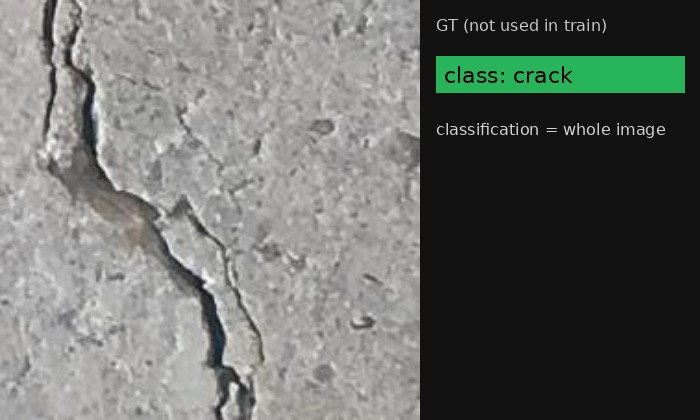

예측


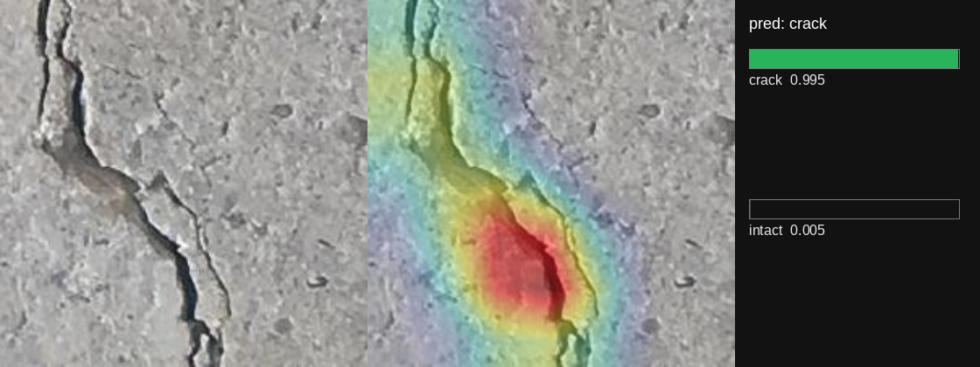


02_crack.jpg pred= crack
  crack    1.000 <--
  intact   0.000
정답


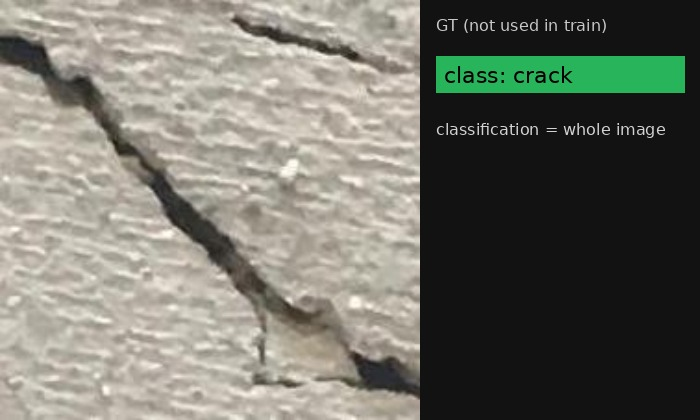

예측


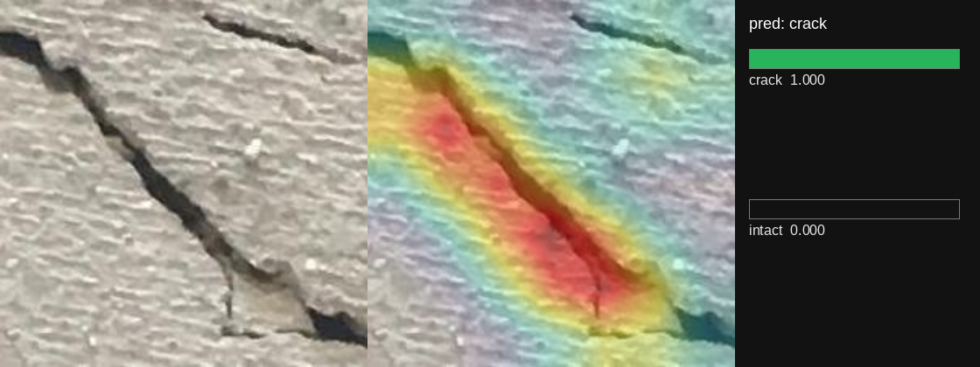


03_intact.jpg pred= intact
  crack    0.000
  intact   1.000 <--
정답


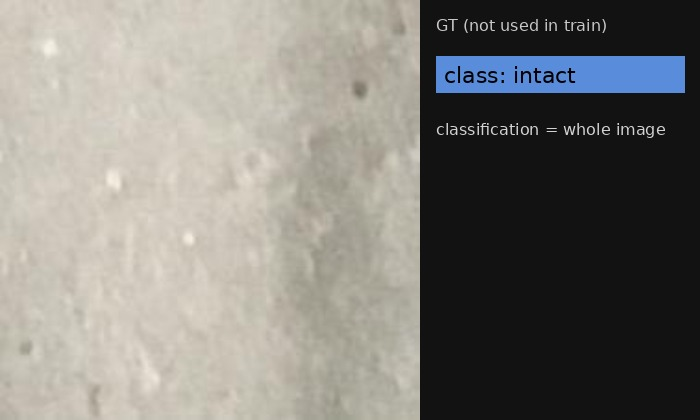

예측


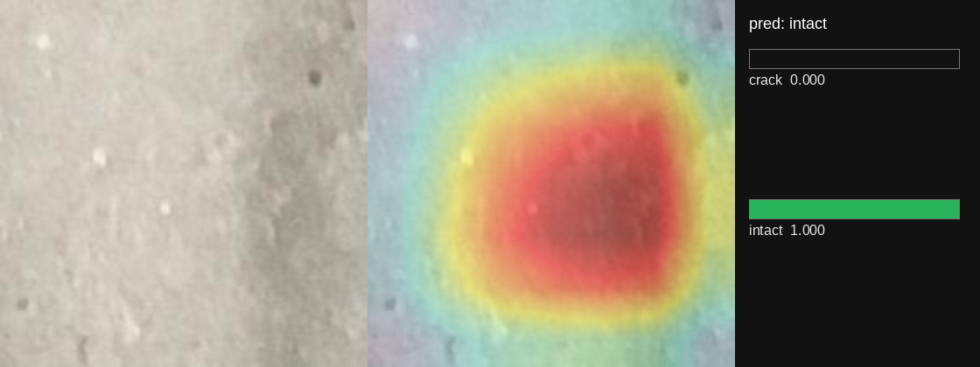

In [9]:
# ==============================================================================
# [셀 9] Grad-CAM 구현 및 예제 이미지 추론 결과 3단 패널(원본 / 히트맵 / 확률) 시각화
# - ResNet18의 layer4에 Forward/Backward Hook을 걸어 Grad-CAM 히트맵을 계산합니다.
# - Jet 컬러맵 변환(jet_rgb) 및 원본 이미지 오버레이(overlay_cam), 확률 막대그래프(draw_probs)
#   함수를 결합하여 examples 폴더 내 샘플 이미지들의 예측 결과와 판단 근거를 출력합니다.
# ==============================================================================
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont
from torchvision import transforms


def font(size):
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size)
        except OSError:
            continue
    return ImageFont.load_default()


def gradcam(model, x, class_idx):
    acts = []
    grads = []

    def fwd(_m, _i, o):
        acts.append(o)

    def bwd(_m, _gi, go):
        grads.append(go[0])

    h1 = model.layer4.register_forward_hook(fwd)
    h2 = model.layer4.register_full_backward_hook(bwd)
    model.zero_grad(set_to_none=True)
    logits = model(x)
    logits[0, class_idx].backward()
    h1.remove()
    h2.remove()

    w = grads[0][0].mean(dim=(1, 2))
    cam = (w[:, None, None] * acts[0][0]).sum(0).relu()
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy()


def jet_rgb(cam):
    x = np.clip(cam, 0.0, 1.0)
    r = np.clip(1.5 - np.abs(4 * x - 3), 0, 1)
    g = np.clip(1.5 - np.abs(4 * x - 2), 0, 1)
    b = np.clip(1.5 - np.abs(4 * x - 1), 0, 1)
    rgb = np.stack([r, g, b], axis=-1)
    return Image.fromarray((rgb * 255).astype(np.uint8), mode="RGB")


def overlay_cam(img, cam):
    heat = Image.fromarray((cam * 255).astype(np.uint8), mode="L").resize(img.size, Image.BILINEAR)
    color = jet_rgb(np.array(heat, dtype=np.float32) / 255.0).resize(img.size, Image.BILINEAR)
    return Image.composite(Image.blend(img, color, 0.55), img, heat)


def draw_probs(classes, prob, pred, width, height):
    panel = Image.new("RGB", (width, height), (18, 18, 18))
    draw = ImageDraw.Draw(panel)
    draw.text((16, 16), f"pred: {classes[pred]}", fill=(255, 255, 255), font=font(18))

    top = 56
    bar_w = width - 40
    row_h = max(48, (height - top - 20) // max(len(classes), 1))
    for i, name in enumerate(classes):
        y = top + i * row_h
        p = float(prob[i])
        fill = (40, 180, 90) if i == pred else (70, 70, 70)
        draw.rectangle([16, y, 16 + int(bar_w * p), y + 22], fill=fill)
        draw.rectangle([16, y, 16 + bar_w, y + 22], outline=(120, 120, 120))
        draw.text((16, y + 26), f"{name}  {p:.3f}", fill=(230, 230, 230), font=font(16))

    return panel


def visualize(raw, cam_ov, classes, prob, pred):
    h, w = 420, 420
    left = raw.resize((w, h), Image.BILINEAR)
    mid = cam_ov.resize((w, h), Image.BILINEAR)
    right = draw_probs(list(classes), prob, pred, 280, h)
    canvas = Image.new("RGB", (w * 2 + 280, h))
    canvas.paste(left, (0, 0))
    canvas.paste(mid, (w, 0))
    canvas.paste(right, (w * 2, 0))
    return canvas


weights = ROOT / "runs" / "best.pt"
ckpt = torch.load(weights, map_location="cpu", weights_only=True)
classes = ckpt["classes"]
imgsz = ckpt.get("imgsz", 224)

model = build_resnet18(num_classes=len(classes), pretrained=False)
model.load_state_dict(ckpt["model"])
model.eval()

tf = transforms.Compose(
    [
        transforms.Resize((imgsz, imgsz)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

images = sorted(
    p
    for p in (ROOT / "examples").glob("*.jpg")
    if not p.name.endswith(("_pred.jpg", "_cam.jpg", "_gt.jpg"))
)

for path in images:
    raw = Image.open(path).convert("RGB")
    x = tf(raw).unsqueeze(0)
    x.requires_grad_(True)
    logits = model(x)
    prob = logits.softmax(1)[0].detach()
    pred = int(prob.argmax())
    cam = gradcam(model, x, pred)
    canvas = visualize(raw, overlay_cam(raw, cam), classes, prob, pred)

    print(path.name, "pred=", classes[pred])
    for i, name in enumerate(classes):
        mark = " <--" if i == pred else ""
        print(f"  {name:8s} {prob[i].item():.3f}{mark}")

    gt = path.parent / f"{path.stem}_gt.jpg"
    if gt.exists():
        print("정답")
        show_img(Image.open(gt), width=720)

    print("예측")
    show_img(canvas, width=980)
    print()
